# SpaceX Falcon 9: Data Wrangling, EDA, Interactive Map and Predictive Analysis

This notebook covers the non-SQL part of the project:

1. Data wrangling and labelling
2. Exploratory data analysis with visualisations
3. Interactive launch-site map (Folium)
4. Predictive analysis: classification of first-stage landing success

The dataset is the processed launch record in `Spacex.csv` (101 launches, 2010 to 2020).

## 1. Setup and data wrangling

In [1]:
import os, re, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
BASE = "/home/claude/spacex"
FIG = f"{BASE}/outputs/figures"
os.makedirs(FIG, exist_ok=True)

raw = pd.read_csv(f"{BASE}/data/Spacex.csv")
df = raw.copy()
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].str.strip()
df = df[df["Date"].notna()].copy()
df["Date"] = pd.to_datetime(df["Date"])
df["Year"] = df["Date"].dt.year
df = df.rename(columns={"PAYLOAD_MASS__KG_": "Payload_kg"})

def booster_family(v):
    m = re.match(r"(F9 v1\.0|F9 v1\.1|F9 FT|F9 B4|F9 B5)", v)
    return m.group(1) if m else "Other"
df["Booster_family"] = df["Booster_Version"].apply(booster_family)

print("Rows:", len(df), "| columns:", df.shape[1])
print("Booster families:", df.Booster_family.value_counts().to_dict())
df.head(3)

Rows: 101 | columns: 12
Booster families: {'F9 B5': 45, 'F9 FT': 24, 'F9 v1.1': 15, 'F9 B4': 12, 'F9 v1.0': 5}


,Date,Time (UTC),Booster_Version,Launch_Site,Payload,Payload_kg,Orbit,Customer,Mission_Outcome,Landing_Outcome,Year,Booster_family
0,2010-06-04,18:45:00,F9 v1.0 B0003,CCAFS LC-40,Dragon Spacecraft Qualification Unit,0,LEO,SpaceX,Success,Failure (parachute),2010,F9 v1.0
1,2010-12-08,15:43:00,F9 v1.0 B0004,CCAFS LC-40,"Dragon demo flight C1, two CubeSats, barrel of...",0,LEO (ISS),NASA (COTS) NRO,Success,Failure (parachute),2010,F9 v1.0
2,2012-05-22,7:44:00,F9 v1.0 B0005,CCAFS LC-40,Dragon demo flight C2,525,LEO (ISS),NASA (COTS),Success,No attempt,2012,F9 v1.0


### Labelling the landing outcome

For classification we need a yes/no target. A landing is a **success** if the outcome starts with `Success` (ground pad or drone ship), and a **failure** if it starts with `Failure`. Launches where no landing was attempted (`No attempt`), where it was precluded, or where the first stage was lost at sea (`Controlled` or `Uncontrolled (ocean)`) are not clear successes or failures, so they are excluded from modelling and kept for EDA.

In [2]:
def landing_class(x):
    if x.startswith("Success"): return 1
    if x.startswith("Failure"): return 0
    return np.nan
df["Landing_class"] = df["Landing_Outcome"].apply(landing_class)

label_counts = df["Landing_Outcome"].value_counts()
print(label_counts.to_string())
print()
print("Modelling rows:", int(df.Landing_class.notna().sum()),
      "| success:", int((df.Landing_class == 1).sum()), "| failure:", int((df.Landing_class == 0).sum()))
df.to_csv(f"{BASE}/data/spacex_clean.csv", index=False)

Landing_Outcome
Success                   38
No attempt                22
Success (drone ship)      14
Success (ground pad)       9
Controlled (ocean)         5
Failure (drone ship)       5
Failure                    3
Failure (parachute)        2
Uncontrolled (ocean)       2
Precluded (drone ship)     1

Modelling rows: 71 | success: 61 | failure: 10


## 2. Exploratory data analysis

**Launch volume and landing success over time.** Landing success is the share of attempted landings that succeeded.

In [3]:
yr = df.groupby("Year").agg(launches=("Date", "size"),
                            landings_attempted=("Landing_class", "count"),
                            landing_successes=("Landing_class", "sum"))
yr["success_rate"] = yr.landing_successes / yr.landings_attempted
yr.round(3)

,launches,landings_attempted,landing_successes,success_rate
Year,,,,
2010,2,2,0.0,0.000
2012,2,0,0.0,NaN
2013,3,0,0.0,NaN
2014,6,0,0.0,NaN
2015,7,3,1.0,0.333
2016,8,8,5.0,0.625
2017,18,14,14.0,1.000
2018,20,11,10.0,0.909
2019,11,10,10.0,1.000


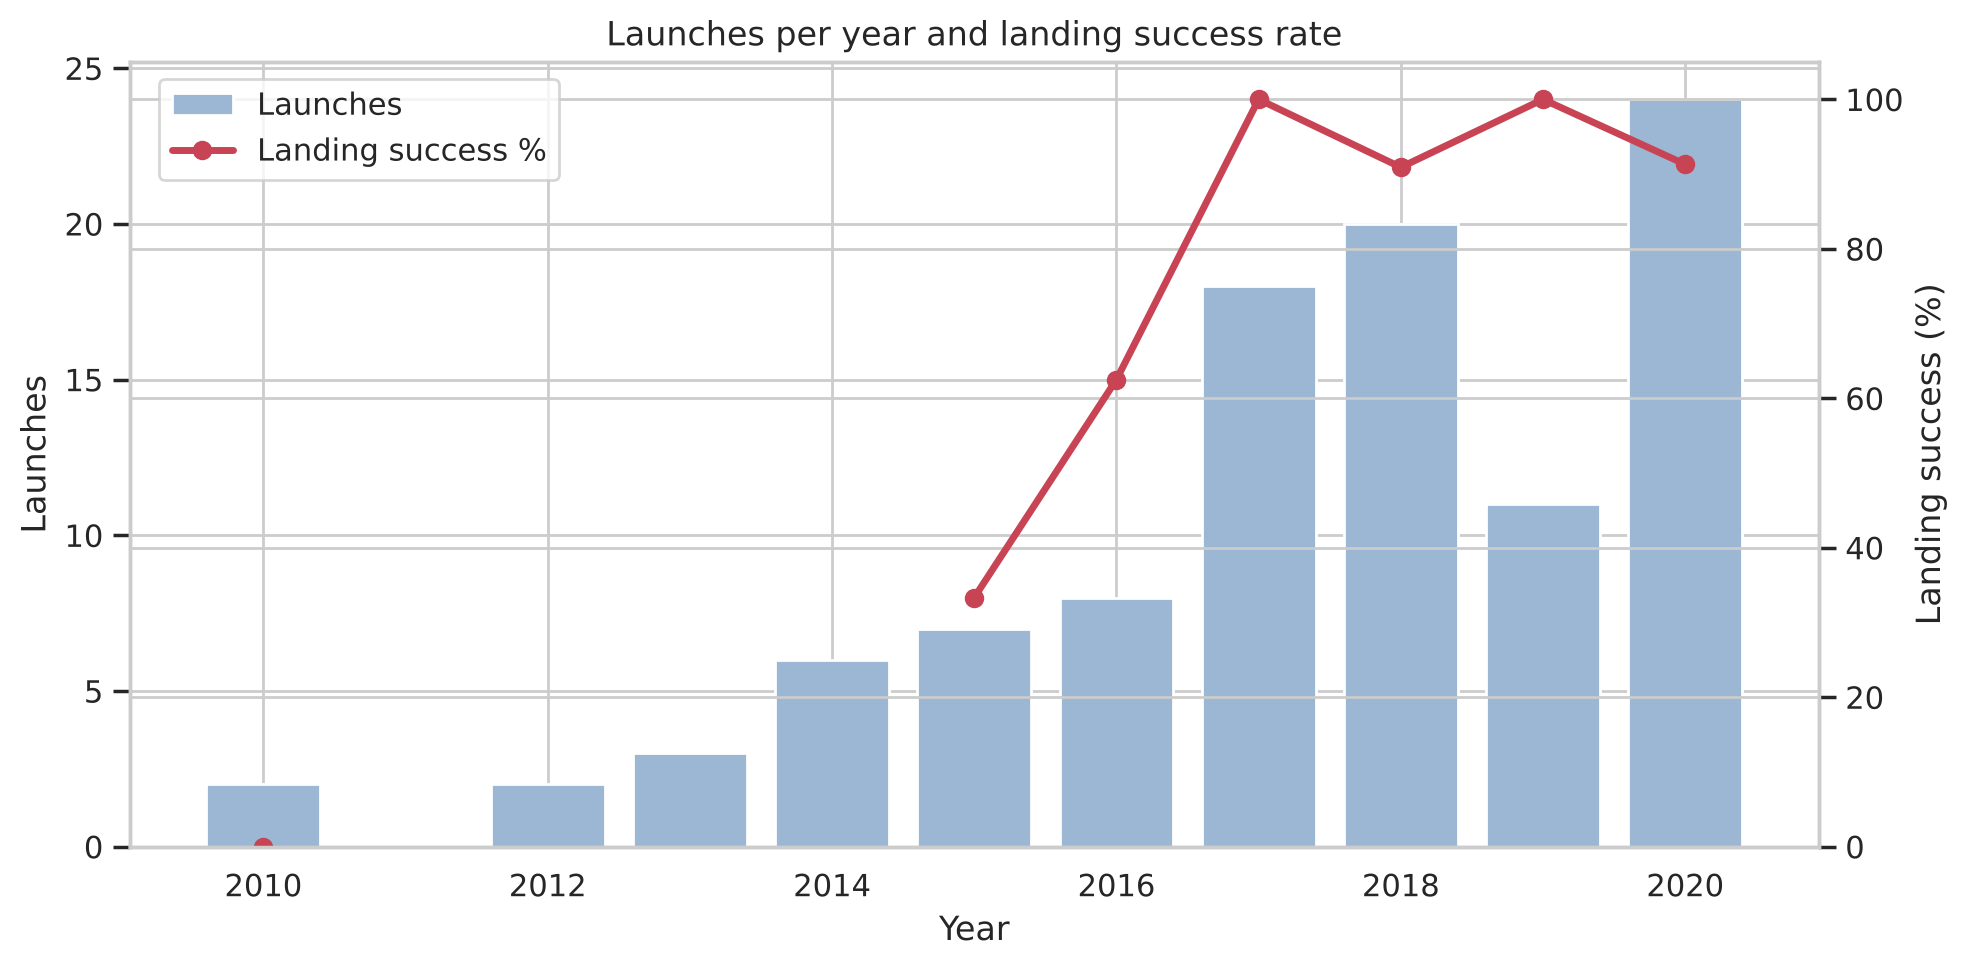

In [4]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(yr.index, yr.launches, color="#9BB7D4", label="Launches")
ax1.set_ylabel("Launches"); ax1.set_xlabel("Year")
ax2 = ax1.twinx()
ax2.plot(yr.index, yr.success_rate * 100, "o-", color="#C84455", lw=2.5, label="Landing success %")
ax2.set_ylabel("Landing success (%)"); ax2.set_ylim(0, 105)
ax1.set_title("Launches per year and landing success rate")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.92))
plt.tight_layout()
plt.savefig(f"{FIG}/launches_success_by_year.png", dpi=160)
plt.show()

**Landing success by launch site and by orbit.**

In [5]:
site = df.groupby("Launch_Site").agg(launches=("Date", "size"),
                                     attempted=("Landing_class", "count"),
                                     successes=("Landing_class", "sum"))
site["success_rate"] = site.successes / site.attempted
site.round(3)

,launches,attempted,successes,success_rate
Launch_Site,,,,
CCAFS LC-40,26,12,6.0,0.500
CCAFS SLC-40,34,27,25.0,0.926
KSC LC-39A,25,21,20.0,0.952
VAFB SLC-4E,16,11,10.0,0.909


In [6]:
orb = df.groupby("Orbit").agg(launches=("Date", "size"),
                              attempted=("Landing_class", "count"),
                              successes=("Landing_class", "sum"))
orb["success_rate"] = orb.successes / orb.attempted
orb = orb[orb.attempted > 0].sort_values("success_rate", ascending=False)
orb.round(3)

,launches,attempted,successes,success_rate
Orbit,,,,
HEO,2,1,1.0,1.000
Polar LEO,8,4,4.0,1.000
MEO,3,2,2.0,1.000
SSO,6,5,5.0,1.000
GTO,30,17,15.0,0.882
LEO,25,24,20.0,0.833
LEO (ISS),26,18,14.0,0.778


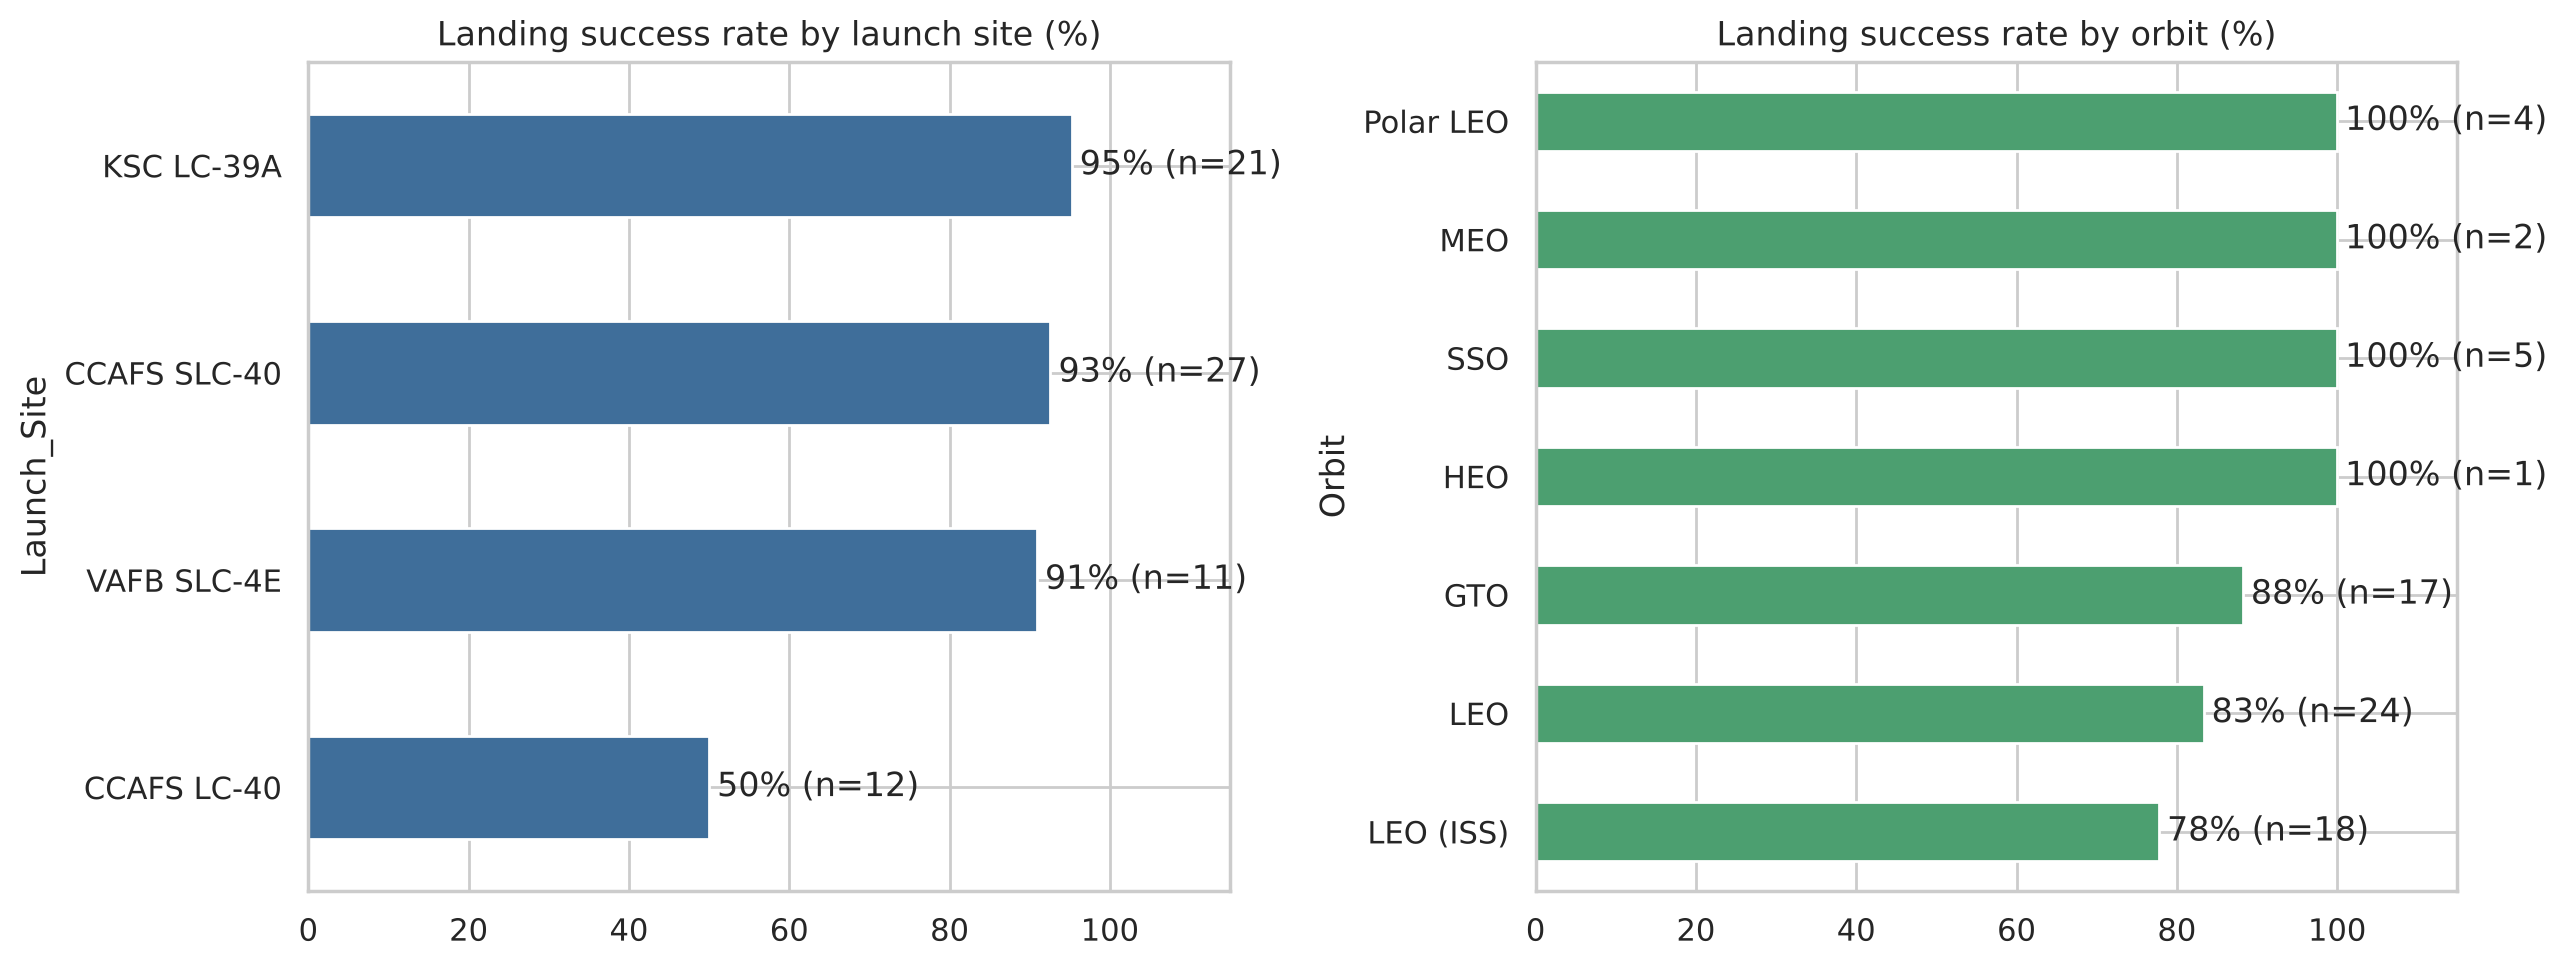

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
site.sort_values("success_rate").success_rate.mul(100).plot.barh(ax=axes[0], color="#3F6E9A")
axes[0].set_title("Landing success rate by launch site (%)"); axes[0].set_xlabel("")
for i, (v, n) in enumerate(zip(site.sort_values("success_rate").success_rate.mul(100), site.sort_values("success_rate").attempted)):
    axes[0].text(v + 1, i, f"{v:.0f}% (n={n})", va="center")
axes[0].set_xlim(0, 115)
orb.sort_values("success_rate").success_rate.mul(100).plot.barh(ax=axes[1], color="#4C9F70")
axes[1].set_title("Landing success rate by orbit (%)"); axes[1].set_xlabel("")
for i, (v, n) in enumerate(zip(orb.sort_values("success_rate").success_rate.mul(100), orb.sort_values("success_rate").attempted)):
    axes[1].text(v + 1, i, f"{v:.0f}% (n={n})", va="center")
axes[1].set_xlim(0, 115)
plt.tight_layout()
plt.savefig(f"{FIG}/success_by_site_and_orbit.png", dpi=160)
plt.show()

**Payload mass versus landing outcome.** Heavier payloads are often assumed to make landings harder, so we check the relationship directly.

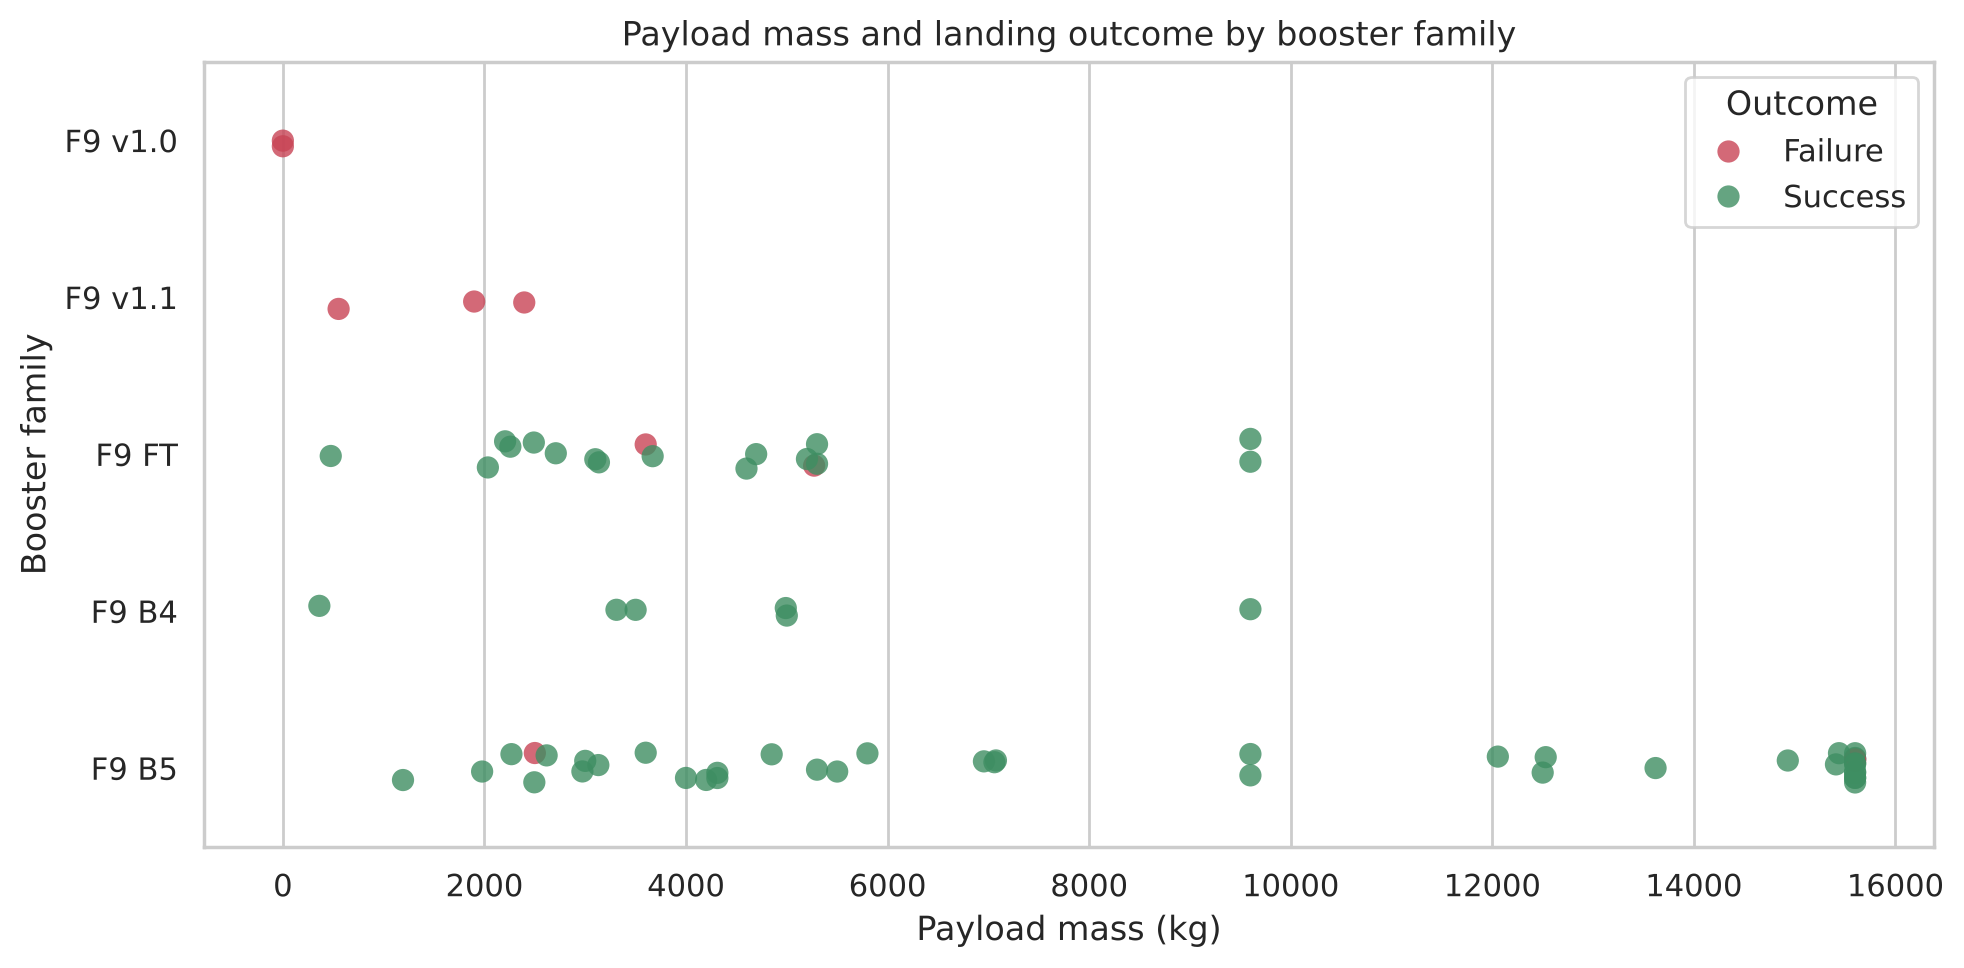

,n,mean_payload,success_rate
Booster_family,,,
F9 B4,6,4460.333,1.000
F9 B5,42,9238.119,0.929
F9 FT,18,4180.056,0.889
F9 v1.0,2,0.000,0.000
F9 v1.1,3,1615.333,0.000


In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
m = df[df.Landing_class.notna()].copy()
m["Outcome"] = m.Landing_class.map({1: "Success", 0: "Failure"})
sns.stripplot(data=m, x="Payload_kg", y="Booster_family", hue="Outcome",
              palette={"Success": "#3E8E62", "Failure": "#C84455"}, size=8, alpha=0.8, ax=ax)
ax.set_xlabel("Payload mass (kg)"); ax.set_ylabel("Booster family")
ax.set_title("Payload mass and landing outcome by booster family")
plt.tight_layout()
plt.savefig(f"{FIG}/payload_vs_outcome.png", dpi=160)
plt.show()
m.groupby("Booster_family").agg(n=("Outcome","size"), mean_payload=("Payload_kg","mean"),
                                success_rate=("Landing_class","mean")).round(3)

**Booster family progression.** Success rate by booster generation shows the effect of design changes over time.

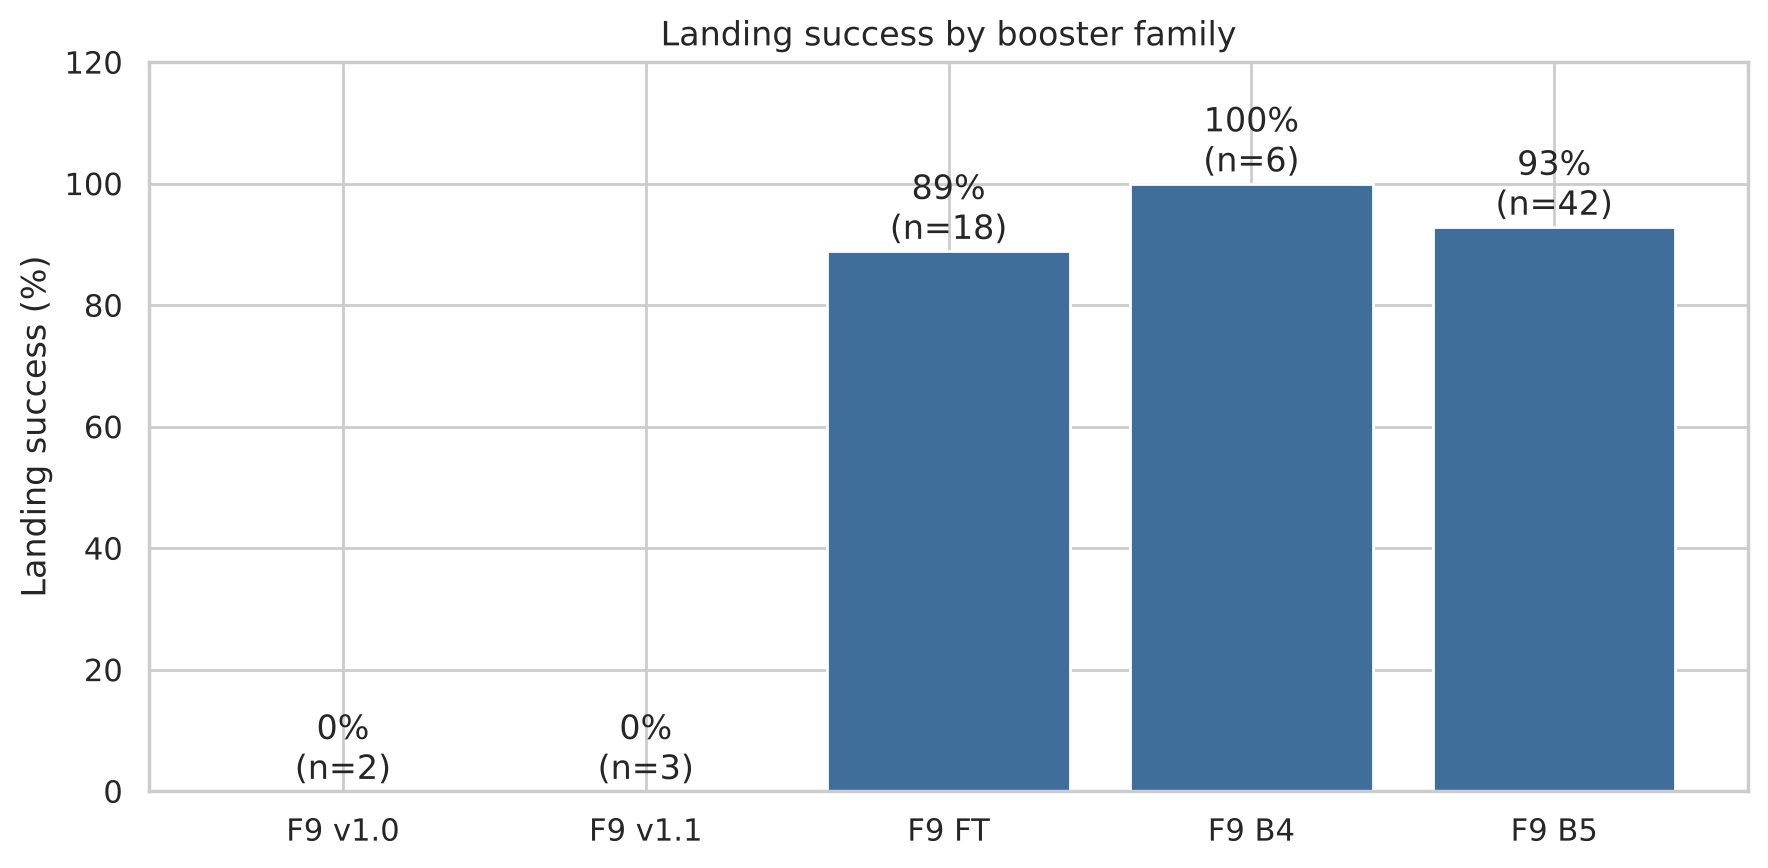

,attempted,success_rate
Booster_family,,
F9 v1.0,2,0.000
F9 v1.1,3,0.000
F9 FT,18,0.889
F9 B4,6,1.000
F9 B5,42,0.929


In [9]:
bf = df[df.Landing_class.notna()].groupby("Booster_family").agg(
    attempted=("Landing_class", "size"), success_rate=("Landing_class", "mean"))
order = ["F9 v1.0", "F9 v1.1", "F9 FT", "F9 B4", "F9 B5"]
bf = bf.reindex([o for o in order if o in bf.index])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(bf.index, bf.success_rate * 100, color="#3F6E9A")
for i, (v, n) in enumerate(zip(bf.success_rate * 100, bf.attempted)):
    ax.text(i, v + 2, f"{v:.0f}%\n(n={n})", ha="center")
ax.set_ylim(0, 120); ax.set_ylabel("Landing success (%)")
ax.set_title("Landing success by booster family")
plt.tight_layout(); plt.savefig(f"{FIG}/booster_family_success.png", dpi=160); plt.show()
bf.round(3)

## 3. Interactive launch-site map (Folium)

The CSV does not include coordinates, so the four launch sites are placed at their published locations (approximate). Markers are coloured by landing success rate, and popups show launch counts.

In [10]:
import folium

SITE_COORDS = {
    "CCAFS LC-40": (28.5623, -80.5774),
    "CCAFS SLC-40": (28.5632, -80.5768),
    "KSC LC-39A": (28.5733, -80.6469),
    "VAFB SLC-4E": (34.6328, -120.6108),
}
m_map = folium.Map(location=[30, -95], zoom_start=4, tiles="CartoDB positron")
for s_name, (lat, lon) in SITE_COORDS.items():
    if s_name not in site.index: continue
    row = site.loc[s_name]
    rate = row.success_rate
    colour = "green" if rate >= 0.8 else ("orange" if rate >= 0.6 else "red")
    popup = (f"<b>{s_name}</b><br>Launches: {int(row.launches)}<br>"
             f"Landings attempted: {int(row.attempted)}<br>"
             f"Successful landings: {int(row.successes)}<br>"
             f"Success rate: {rate*100:.0f}%")
    folium.Marker([lat, lon], popup=folium.Popup(popup, max_width=260),
                  tooltip=f"{s_name}: {rate*100:.0f}% landing success",
                  icon=folium.Icon(color=colour, icon="rocket", prefix="fa")).add_to(m_map)
    folium.Circle([lat, lon], radius=int(row.launches) * 900,
                  color=colour, fill=True, fill_opacity=0.15).add_to(m_map)
m_map.save(f"{BASE}/outputs/launch_sites_map.html")
print("Map saved; sites plotted:", len([s for s in SITE_COORDS if s in site.index]))

Map saved; sites plotted: 4


## 4. Predictive analysis: classification of landing success

**Features:** launch site, orbit, booster family, payload mass, and launch year. Categorical features are one-hot encoded, and payload mass is standardised inside the pipeline.

**Models compared:** logistic regression, support vector machine, decision tree and k-nearest neighbours. Each is tuned with 5-fold cross-validation on a stratified 80% training split. The 20% test split is used once at the end.

In [11]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

model_df = df[df.Landing_class.notna()].copy()
X = model_df[["Launch_Site", "Orbit", "Booster_family", "Payload_kg", "Year"]]
y = model_df["Landing_class"].astype(int)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("train:", len(X_tr), "| test:", len(X_te), "| success share (train):", round(y_tr.mean(), 3))

pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["Launch_Site", "Orbit", "Booster_family"]),
    ("num", StandardScaler(), ["Payload_kg", "Year"]),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
candidates = {
    "Logistic regression": (LogisticRegression(max_iter=5000),
                            {"clf__C": [0.01, 0.1, 1, 10]}),
    "SVM": (SVC(probability=True, random_state=42),
            {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.1]}),
    "Decision tree": (DecisionTreeClassifier(random_state=42),
                      {"clf__max_depth": [2, 3, 4, 5, None], "clf__min_samples_split": [2, 5]}),
    "K-nearest neighbours": (KNeighborsClassifier(),
                             {"clf__n_neighbors": [3, 5, 7, 9], "clf__weights": ["uniform", "distance"]}),
}
results, fitted = [], {}
for name, (est, grid) in candidates.items():
    pipe = Pipeline([("pre", pre), ("clf", est)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="accuracy", n_jobs=1).fit(X_tr, y_tr)
    test_pred = gs.best_estimator_.predict(X_te)
    results.append({"model": name, "cv_accuracy": gs.best_score_,
                    "test_accuracy": accuracy_score(y_te, test_pred), "best_params": str(gs.best_params_)})
    fitted[name] = (gs.best_estimator_, test_pred)
res_df = pd.DataFrame(results).sort_values("cv_accuracy", ascending=False)  # select on CV, never on the test set
res_df.to_csv(f"{BASE}/outputs/model_comparison.csv", index=False)
res_df.round(3)

train: 56 | test: 15 | success share (train): 0.857


,model,cv_accuracy,test_accuracy,best_params
0,Logistic regression,0.909,0.933,{'clf__C': 1}
1,SVM,0.876,0.933,"{'clf__C': 10, 'clf__gamma': 'scale'}"
3,K-nearest neighbours,0.874,0.867,"{'clf__n_neighbors': 3, 'clf__weights': 'unifo..."
2,Decision tree,0.821,0.933,"{'clf__max_depth': 2, 'clf__min_samples_split'..."


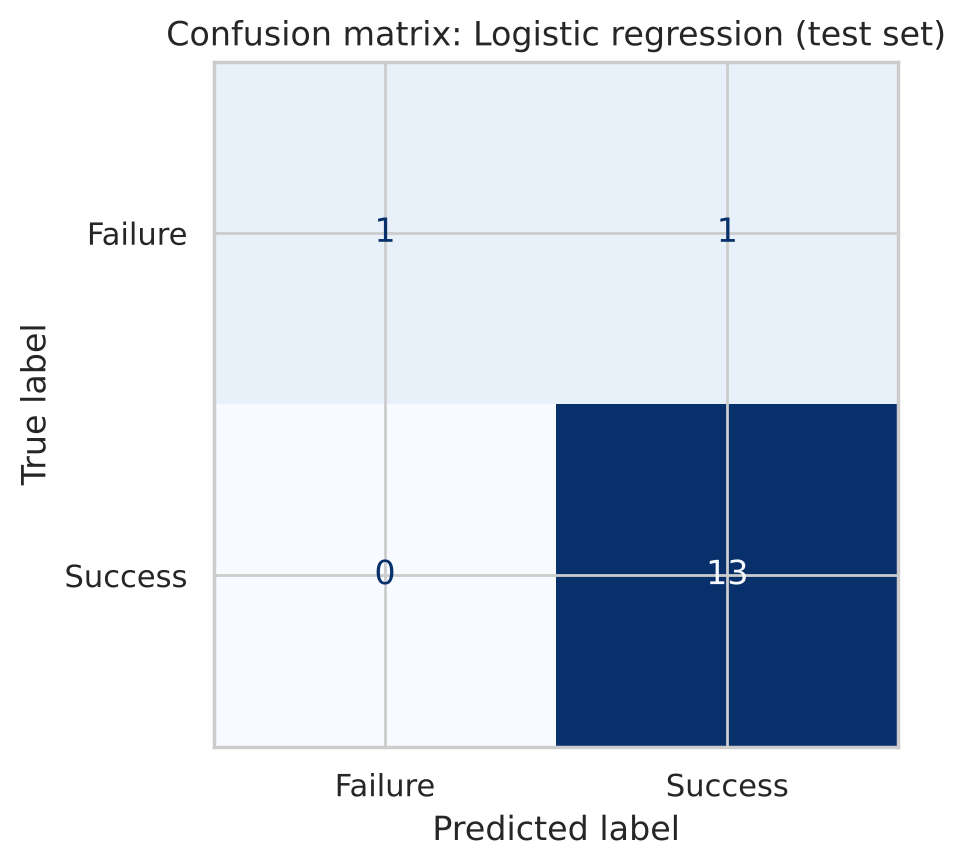

Best model: Logistic regression | test accuracy: 0.933
[[ 1  1]
 [ 0 13]]


In [12]:
best_name = res_df.iloc[0].model  # chosen by cross-validation accuracy
best_pipe, best_pred = fitted[best_name]
cm = confusion_matrix(y_te, best_pred)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["Failure", "Success"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion matrix: {best_name} (test set)")
plt.tight_layout(); plt.savefig(f"{FIG}/confusion_matrix.png", dpi=160); plt.show()
print("Best model:", best_name, "| test accuracy:", round(accuracy_score(y_te, best_pred), 3))
print(cm)

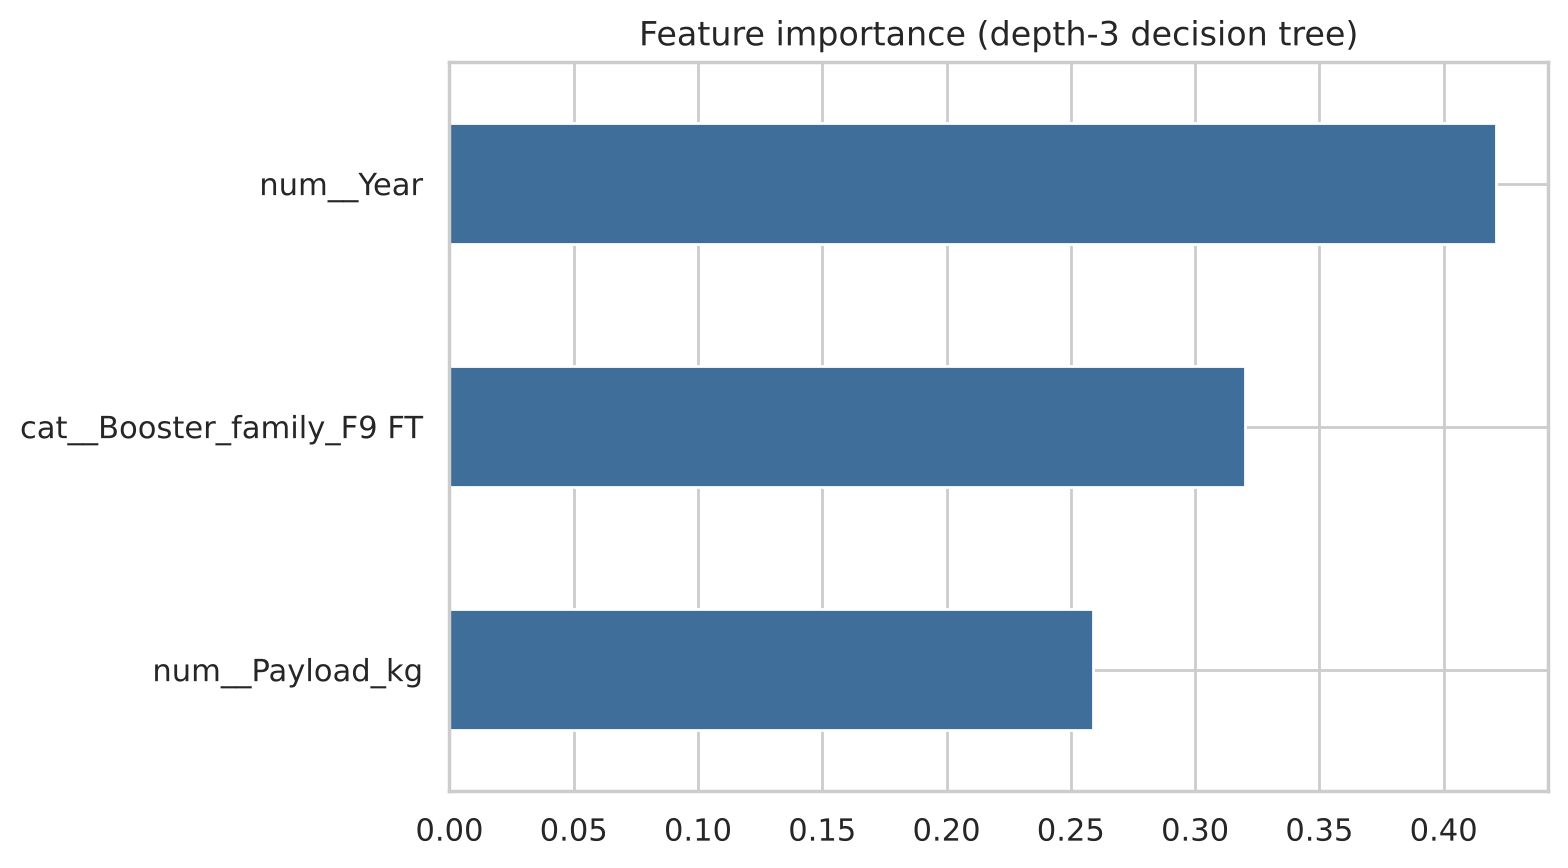

num__Year                    0.421
cat__Booster_family_F9 FT    0.320
num__Payload_kg              0.259
dtype: float64

In [13]:
# Which features drive the best tree-based view? Use a shallow tree for interpretability.
tree_pipe = Pipeline([("pre", pre), ("clf", DecisionTreeClassifier(max_depth=3, random_state=42))]).fit(X_tr, y_tr)
names = tree_pipe.named_steps["pre"].get_feature_names_out()
imp = pd.Series(tree_pipe.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)
imp = imp[imp > 0]
fig, ax = plt.subplots(figsize=(8, 4.5))
imp.sort_values().plot.barh(ax=ax, color="#3F6E9A")
ax.set_title("Feature importance (depth-3 decision tree)")
plt.tight_layout(); plt.savefig(f"{FIG}/feature_importance.png", dpi=160); plt.show()
imp.round(3)

## 5. Summary

In [14]:
summary = {
    "launches": int(len(df)),
    "modelling_rows": int(len(model_df)),
    "overall_landing_success_rate": round(float(model_df.Landing_class.mean()), 3),
    "best_model": best_name,
    "best_test_accuracy": round(float(accuracy_score(y_te, best_pred)), 3),
}
pd.Series(summary)

launches                                        101
modelling_rows                                   71
overall_landing_success_rate                  0.859
best_model                      Logistic regression
best_test_accuracy                            0.933
dtype: object